In [1]:
import cv2
import glob
import os 
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt 

matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [2]:
prefix = '/groups/karashchuk/karashchuklab/animal-datasets-processed/posetail-pretraining-v6'
animal_prefix = os.path.join(prefix, 'po-animal-sub256-motion', 'train')
# human_prefix = os.path.join(prefix, 'point-odyssey-human', 'train')
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v2'

540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960
540 960


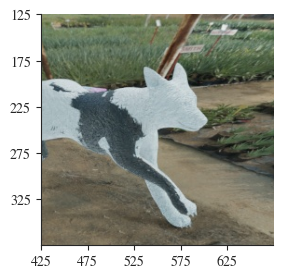

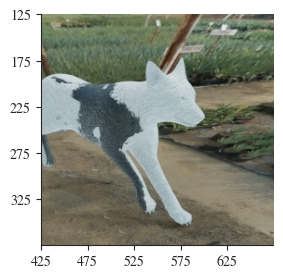

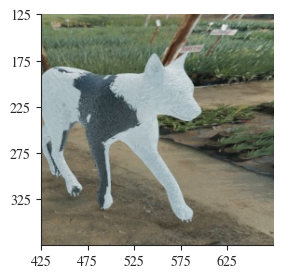

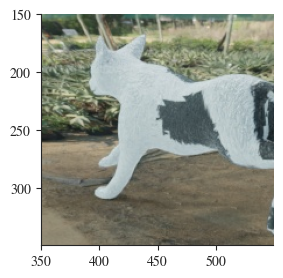

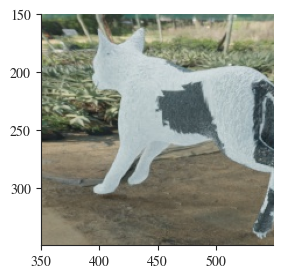

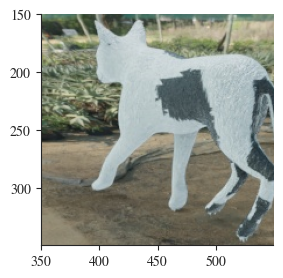

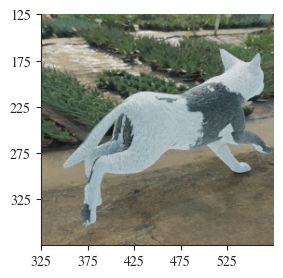

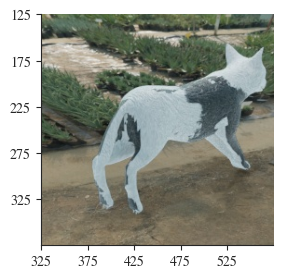

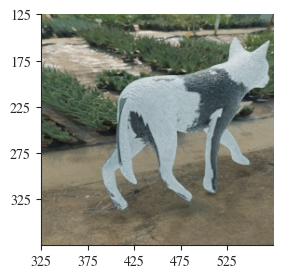

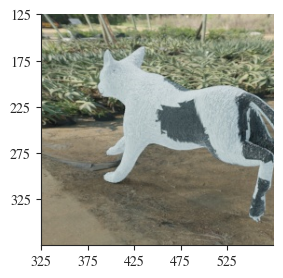

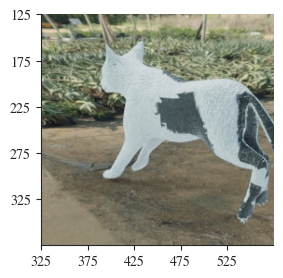

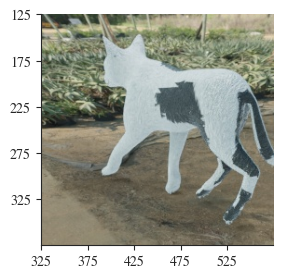

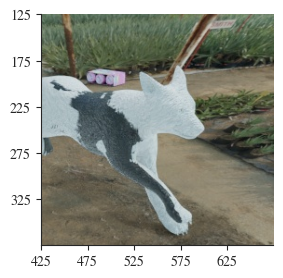

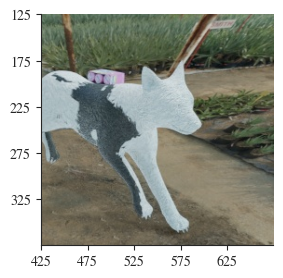

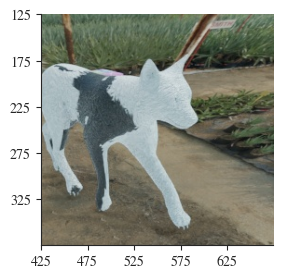

In [4]:
# trial = 'ani10'
# views = ['view4', 'view8']
# frames = [0, 20, 30]
# crop_size = 100
# x = 470
# y = 275

trial = 'ani3'
views = ['view1', 'view4', 'view5', 'view6', 'view7']
frames = [205, 210, 215]
crops = {
    'view1': {'x': 550, 'y': 250, 'crop_size': 125},
    'view4': {'x': 450, 'y': 250, 'crop_size': 100},
    'view5': {'x': 450, 'y': 250, 'crop_size': 125},
    'view6': {'x': 450, 'y': 250, 'crop_size': 125},
    'view7': {'x': 550, 'y': 250, 'crop_size': 125},
}
views = list(crops.keys())

show_ticks = True 

# subplots for 3dpop fig 1 - rgbs from multiple views (rows) for multiple frames (cols)
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fs = 18

counter = 0

for i, view in enumerate(views):
    for j, frame in enumerate(frames): 

        fig, ax = plt.subplots(1, 1, figsize = (3, 3))
        video_prefix = os.path.join(animal_prefix, trial, 'trial', 'img', view)
        img_paths = sorted(glob.glob(os.path.join(video_prefix, '*.jpg')))
        img_path = img_paths[frame]
        # img_path = os.path.join(video_prefix, f"img{str(frame).zfill(6)}.jpg")
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        h, w = img.shape[:2]
        print(h, w)
        c = crops[views[i]]
        cx, cy, crop_size = c['x'], c['y'], c['crop_size']
        img = img[cy - crop_size : cy + crop_size, cx - crop_size : cx + crop_size]

        ax.imshow(img, aspect = 'auto')

        if show_ticks: 
            ax.set_xticks(range(0, 2*crop_size, 50))
            ax.set_xticklabels(range(cx - crop_size, cx + crop_size, 50))
            ax.set_yticks(range(0, 2*crop_size, 50))
            ax.set_yticklabels(range(cy - crop_size, cy + crop_size, 50))

        else: 
            ax.set_xticks([])
            ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        outdir = os.path.dirname(outpath)
        if outdir:
            os.makedirs(outdir, exist_ok=True)

        counter += 1
        sns.despine(left = False, bottom = False)
        frame_str = '_'.join(str(f) for f in frames)
        out_prefix = os.path.join(outpath, 'po_architecture', trial, view)
        os.makedirs(out_prefix, exist_ok = True)
        fig.savefig(os.path.join(out_prefix, f'{frame}.pdf'), dpi=800, bbox_inches='tight')   
